## Example #2. Analysis on PicoQuant's photon data
This is a step-by-step guide of IFCA analysis on experimentally obtained photon data using a PicoQuant TCSPC module.

First, we import the `IFCA` module and other python libraries that are used in this notebook.
Note that `pqreader` (from `phconvert`) is necessary for loading photon data stored in the PicoQuant format (`.ptu`).
For installation of `phconvert`, please refer to http://photon-hdf5.github.io/phconvert/.

In [1]:
%%capture
import matplotlib.pyplot as plt
import numpy as np
from phconvert import pqreader
import IFCA

#### Setting parameters
Then, we set the parameters that are necessary for IFCA analysis as a Python dictionary.

In [2]:
param = {}

`clock` is the unit of macrotime (timestamp) represented in seconds.

In [3]:
param["clock"] = 20e-9

By setting a nonzero value to `gap` (unit: clock),  we can take account of the dead time of the detector/TCSPC module. It can also be used to mitigate the effect of afterpulsing.

In [4]:
param["gap"] = 100

`bin_time` (unit: second) sets the binning size of the macrotime to be used in construction of tensors. It determines the time resolution of IFCA analysis.

In [5]:
param["bin_time"] = 20e-6

`detector_list` is a list of detectors used in the analysis. Numbers in the list correspond to the index of detectors in the photon data. Fluorescence decay pattern will be sorted in the same order as this list. 

In [6]:
param["detector_list"] = [0, 1]

`tcspc_num_ch` is the number of channels of the TCSPC module. `tcspc_bin_factor` is the number of TCSPC channels binned together in IFCA analysis. Usually, we set `tcspc_bin_factor` approximately equal to `tcspc_num_ch * num_detectors / 256`.

In [7]:
param["tcspc_num_ch"] = 1280
param["tcspc_bin_factor"] = 10

#### Loading photon data and making tensors
The location of the photon data file is specified by the file path (`path`).

In [8]:
path = ""

If we analyze only a single data file, then we can simply specify its file name (`file_name`).

In [9]:
file_name = "5nt_1_x40,00µm_y40,00µm_z8,00µm_1.ptu"

We load the photon data into a Python dictionary `d_photon`.

In [10]:
d_photon = dict(zip(("timestamp", "detector", "nanotime"),
    pqreader.load_ptu(path+file_name, )))

And construct tensors from the photon data.

In [11]:
d_tensor, bin_num = IFCA.make_tensors(**param, d_photon=d_photon)

Alternatively, we can analyze multiple files stored under the specified file path and sum up the results to improve the signal-to-noise ratio. In this case, the data files to be analyzed are selected by specifying a filter string (`file_name_pattern`) which represents the file name using wildcards. For example, if the file names are `data1`, `data2`, `data3`, we can select all by setting `file_name_pattern = "data*"`.

In [12]:
# file_name_pattern = "5nt*.ptu"

Then, we load photon data and make tensors.

In [13]:
# d_tensor, num_files, photons, bin_num = IFCA.accumulate_tensors(
#    loader=pqreader.load_ptu,
#    args=(),
#    path=path,
#    file_name_pattern=file_name_pattern,
#    **param
#    )

Let's plot the 1D tensor, i.e., the ensemble decay.

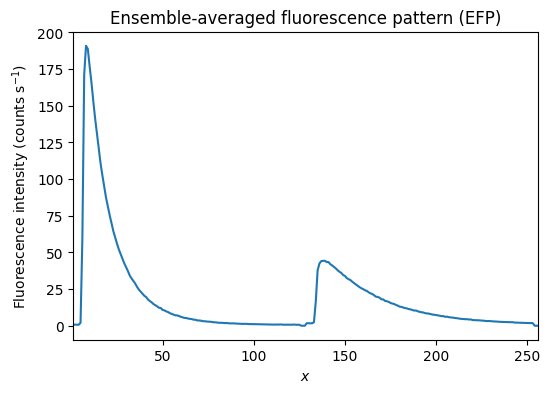

In [14]:
fig = plt.figure(figsize=(6,4))
ax = fig.add_subplot(1,1,1, title="Ensemble-averaged fluorescence pattern (EFP)")
ax.plot(range(1,len(d_tensor["vector"])+1),d_tensor["vector"]/param["bin_time"])
ax.set_xlabel("$x$")
ax.set_ylabel("Fluorescence intensity (counts s$^{-1}$)")
ax.margins(x=0)
plt.show()

#### Eigenvalue analysis
Next, we apply the eigenvalue decomposition to the obtaind 2D matrix.

In [15]:
d_eig = IFCA.eigenvalue_analysis(d_tensor)

Let's check the result of eigenvalue analysis.

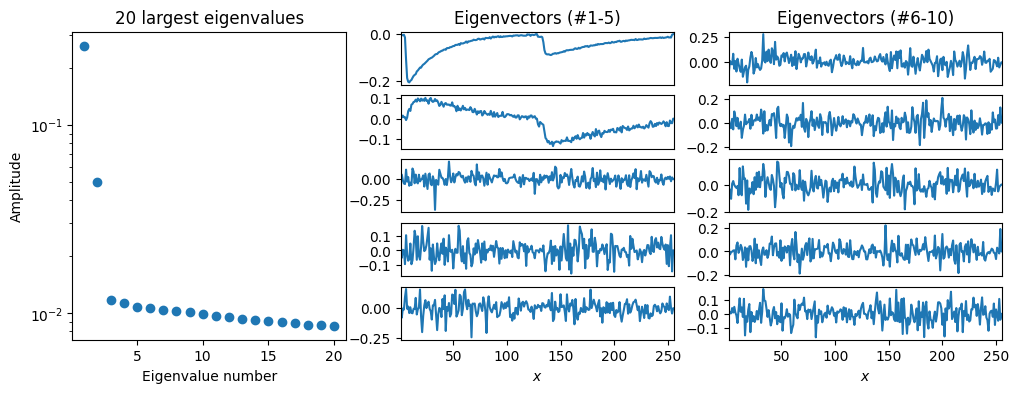

In [16]:
fig = plt.figure(figsize=(12,4))
ax = fig.add_subplot(1,3,1, title="20 largest eigenvalues")
ax.plot(range(1,21), d_eig["eigenvalue"][:20], marker="o", linewidth=0)
ax.set_yscale("log")
ax.set_ylabel("Amplitude")
ax.set_xlabel("Eigenvalue number")
ax.set_xlim(left=0.1, right=20.9)
ax0 = fig.add_subplot(5,3,2, title="Eigenvectors (#1-5)")
ax0.plot(range(1,len(d_tensor["vector"])+1),d_eig["eigenvector"][:,0])
ax0.margins(x=0)
ax0.set_xticks([])
ax1 = fig.add_subplot(5,3,5)
ax1.plot(range(1,len(d_tensor["vector"])+1),d_eig["eigenvector"][:,1])
ax1.margins(x=0)
ax1.set_xticks([])
ax2 = fig.add_subplot(5,3,8)
ax2.plot(range(1,len(d_tensor["vector"])+1),d_eig["eigenvector"][:,2])
ax2.margins(x=0)
ax2.set_xticks([])
ax3 = fig.add_subplot(5,3,11)
ax3.plot(range(1,len(d_tensor["vector"])+1),d_eig["eigenvector"][:,3])
ax3.margins(x=0)
ax3.set_xticks([])
ax4 = fig.add_subplot(5,3,14)
ax4.plot(range(1,len(d_tensor["vector"])+1),d_eig["eigenvector"][:,4])
ax4.margins(x=0)
ax4.set_xlabel("$x$")
ax5 = fig.add_subplot(5,3,3, title="Eigenvectors (#6-10)")
ax5.plot(range(1,len(d_tensor["vector"])+1),d_eig["eigenvector"][:,5])
ax5.margins(x=0)
ax5.set_xticks([])
ax6 = fig.add_subplot(5,3,6)
ax6.plot(range(1,len(d_tensor["vector"])+1),d_eig["eigenvector"][:,6])
ax6.margins(x=0)
ax6.set_xticks([])
ax7 = fig.add_subplot(5,3,9)
ax7.plot(range(1,len(d_tensor["vector"])+1),d_eig["eigenvector"][:,7])
ax7.margins(x=0)
ax7.set_xticks([])
ax8 = fig.add_subplot(5,3,12)
ax8.plot(range(1,len(d_tensor["vector"])+1),d_eig["eigenvector"][:,8])
ax8.margins(x=0)
ax8.set_xticks([])
ax9 = fig.add_subplot(5,3,15)
ax9.plot(range(1,len(d_tensor["vector"])+1),d_eig["eigenvector"][:,9])
ax9.margins(x=0)
ax9.set_xlabel("$x$")
plt.show()

#### Diagonalization of the 3D tensor
From the above eigenvalue plot, we can set the number of IFCs (`num_IFC`).

In [17]:
num_IFC = 2

Finally, we identify the IFCs by fitting the 3D tensor.

In [18]:
IFCA_result = IFCA.find_IFC(**d_eig, n=num_IFC, maxiter=1000, tol=1e-13, trial=10)

Trial 1 : Residual = 5.637856514913206e-07 , number of sweeps = 2
Trial 2 : Residual = 5.637856498240817e-07 , number of sweeps = 2
Trial 3 : Residual = 5.637856498178556e-07 , number of sweeps = 2
Trial 4 : Residual = 5.637856493331547e-07 , number of sweeps = 2
Trial 5 : Residual = 5.637872461396511e-07 , number of sweeps = 2
Trial 6 : Residual = 5.637856554419038e-07 , number of sweeps = 2
Trial 7 : Residual = 5.637856592980283e-07 , number of sweeps = 2
Trial 8 : Residual = 5.6378564930175e-07 , number of sweeps = 2
Trial 9 : Residual = 5.637856513601699e-07 , number of sweeps = 2
Trial 10 : Residual = 5.637856493885896e-07 , number of sweeps = 2
Residual, best of 10 trials = 5.6378564930175e-07


Let's check how well the original 3D tensor is reproduced by the obtained IFCs.

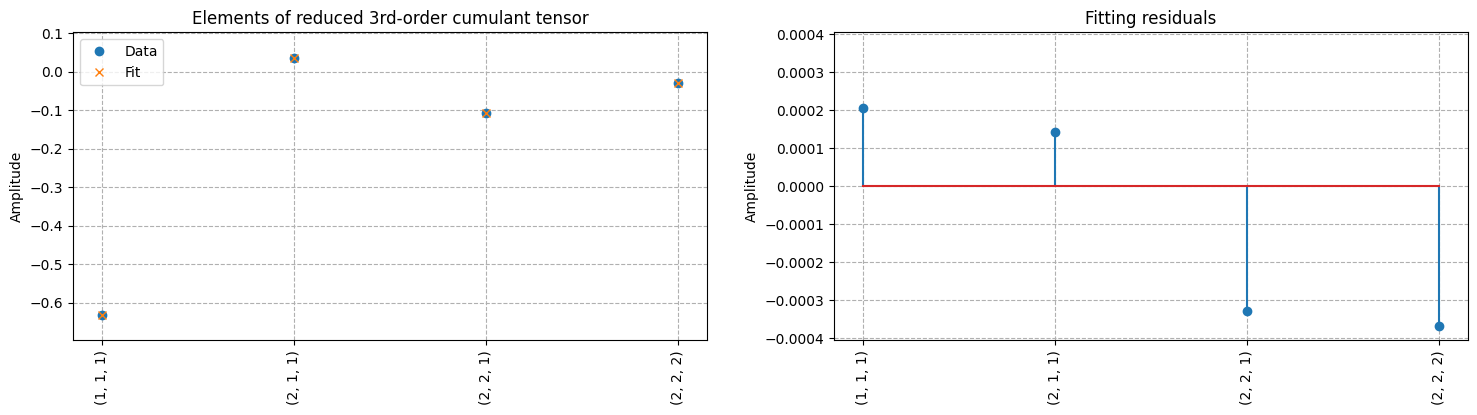

In [19]:
obs_1D = np.zeros(num_IFC*(num_IFC+1)*(num_IFC+2)//6)
fit_1D = np.zeros(num_IFC*(num_IFC+1)*(num_IFC+2)//6)
res_1D = np.zeros(num_IFC*(num_IFC+1)*(num_IFC+2)//6)
element = []
index = 0
for i in range(0, num_IFC):
    for j in range (0, i+1):
        for k in range(0, j+1):
            obs_1D[index] = IFCA_result["observed_tensor"][i, j, k]
            fit_1D[index] = IFCA_result["fitted_tensor"][i, j, k]
            element.append(str(tuple([i+1, j+1, k+1])))
            index += 1
res_1D = obs_1D - fit_1D
fig = plt.figure(figsize=(18,4))
ax = fig.add_subplot(121, title="Elements of reduced 3rd-order cumulant tensor")
ax.plot(element, obs_1D, "o", label='Data')
ax.plot(element, fit_1D, "x", label='Fit')
ax.set_ylabel("Amplitude")
ax.tick_params(axis="x", labelrotation=90)
ax.set_axisbelow(True)
ax.grid(ls="--")
ax.legend()
ax.margins(y=0.1)
ax2 = fig.add_subplot(122, title="Fitting residuals")
ax2.stem(element, res_1D)
ax2.set_axisbelow(True)
ax2.grid(ls="--")
ax2.set_ylabel("Amplitude")
ax2.set_ylim(-1.1*max(abs(res_1D)), 1.1*max(abs(res_1D)))
ax2.tick_params(axis="x", labelrotation=90)
plt.show()

#### Results
The obtained IFCs are visualized as follows.

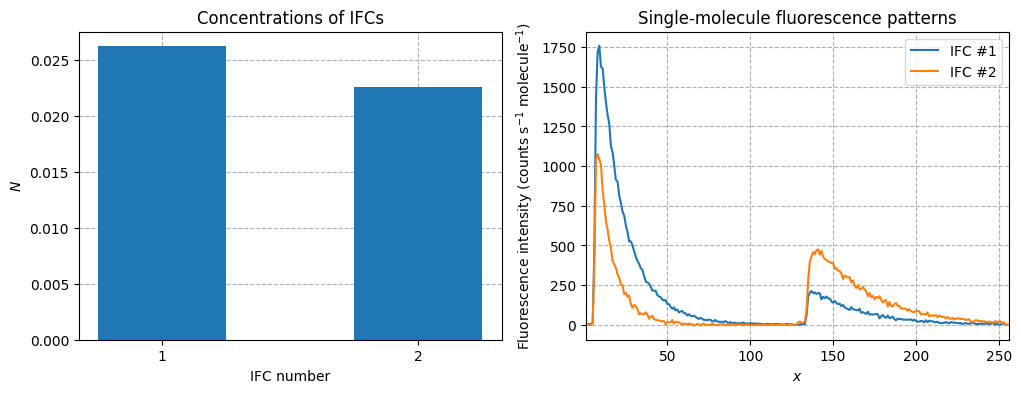

In [20]:
N_IFCA = IFCA_result["number_of_molecules_from_M&T"]
D = IFCA_result["single_molecule_decay"]
fig = plt.figure(figsize=(12, 4))
ax = fig.add_subplot(121, title="Concentrations of IFCs")
ax.grid(ls="--")
ax.bar(range(1,len(N_IFCA)+1), N_IFCA, align="center", width=0.5, label="Estimated from M&T")
ax.set_xticks(np.arange(1,len(N_IFCA)+1,step=1))
ax.set_ylabel("$N$")
ax.set_xlabel("IFC number")
ax.set_axisbelow(True)
ax.grid(ls="--")
ax2 = fig.add_subplot(122, title="Single-molecule fluorescence patterns")
ax2.plot(range(1,len(d_tensor["vector"])+1), D/param["bin_time"])
ax2.legend(labels=["IFC #"+str(i) for i in range(1, D.shape[1]+1)])
ax2.set_ylabel("Fluorescence intensity (counts s$^{-1}$ molecule$^{-1}$)")
ax2.set_xlabel("$x$")
ax2.set_axisbelow(True)
ax2.grid(ls="--")
ax2.margins(x=0)
plt.show()